# EDA 00 · Population, label and coverage

**Question.** Who are we predicting for, what exactly does `is_churn` mean, and how much information do we have about each customer?

**Population.** February cohort (`train.parquet`), `fit` part of the development split only: 744,699 customers. `stop`, `tune` and the March cohort are never inspected with their labels in this series.

**As-of rule.** Only records dated on or before the feature cutoff, **2017-01-31**, are used. Section 2 shows why this rule is not optional.

**Outputs.** Figures in `eda/figures/00_*.png`; the closing decisions table is written to `eda/DECISIONS.md`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl

EDA_DIR = next(p for p in (Path.cwd(), Path.cwd() / "eda") if (p / "_common.py").exists())
sys.path.insert(0, str(EDA_DIR))
import _common as C

pl.Config.set_tbl_rows(30)
pd.options.display.float_format = "{:,.4f}".format
pd.set_option("display.max_colwidth", None)

## 1. Population and split

The development cohort is split once into `fit` / `stop` / `tune` (75 / 12.5 / 12.5 %) with a salted SHA-1 hash of `msno`, stratified by label. `_common.load_cohort()` reproduces that rule; the check below compares it with the indices saved by the w1 and w2 model runs.

In [2]:
cohort = C.load_cohort()
split_table = (cohort.group_by("split")
               .agg(n=pl.len(), churners=pl.col("is_churn").sum(), churn_rate=pl.col("is_churn").mean())
               .sort("split"))
split_table

split,n,churners,churn_rate
str,u32,i64,f64
"""fit""",744699,47604,0.063924
"""stop""",124117,7934,0.063924
"""tune""",124115,7933,0.063917


In [3]:
fit_rows = np.sort(cohort.filter(pl.col("split") == "fit")["row"].to_numpy())
for run in ("w1/artifacts/sherlock_w1/split_indices.npz",
            "w2/artifacts/sherlock_w2/feature_preparation/split_indices.npz"):
    path = C.WORKSHOPS_DIR / run
    if path.exists():
        ref = np.sort(np.load(path)["fit"])
        print(f"{run}: identical fit rows = {np.array_equal(fit_rows, ref)}")

w1/artifacts/sherlock_w1/split_indices.npz: identical fit rows = True
w2/artifacts/sherlock_w2/feature_preparation/split_indices.npz: identical fit rows = True


In [4]:
users = C.load_fit_population()
BASE = users["is_churn"].mean()
print(f"fit customers: {users.height:,} | churners: {users['is_churn'].sum():,} | base rate: {BASE:.4%}")

fit customers: 744,699 | churners: 47,604 | base rate: 6.3924%


## 2. Why the as-of rule matters

Both transaction files extend past the cutoff: `transactions.parquet` already contains February 2017, and `transactions_v2.parquet` adds February and March. A February customer who renews does so *in February*, so any record after 2017-01-31 is the label itself.

In [5]:
txn_all = (C.scan_transactions(users, as_of=False)
           .select("msno", "source", "transaction_date").collect(engine="streaming"))
(txn_all.with_columns(month=(pl.col("transaction_date") // 100))
        .filter(pl.col("month") >= 201612)
        .group_by("source", "month").agg(records=pl.len())
        .sort("source", "month"))

source,month,records
i8,i32,u32
1,201612,684005
1,201701,735662
1,201702,639308
2,201612,2122
2,201701,5050
2,201702,79160
2,201703,708832


In [6]:
future = (txn_all.filter(pl.col("transaction_date") > C.CUTOFF_INT)
          .select("msno").unique().with_columns(has_record_after_cutoff=pl.lit(1, pl.Int8)))
leak = users.join(future, on="msno", how="left").with_columns(pl.col("has_record_after_cutoff").fill_null(0))
C.churn_rate_by(leak, "has_record_after_cutoff")[["has_record_after_cutoff", "n", "churners", "churn_rate"]]

,has_record_after_cutoff,n,churners,churn_rate
0,0,24405,24405,1.0000
1,1,720294,23199,0.0322


A customer **without** a transaction after the cutoff churns 100 % of the time; with one, 3.2 %. A single post-cutoff record almost reproduces the label, so every table in this series is filtered with `transaction_date <= 20170131` (`C.scan_transactions(..., as_of=True)`), and the listening logs with `date` in the 90-day window ending at the cutoff. The legacy EDA plotted `transactions_v2` without this filter, which is one reason its conclusions are not reused. Both production pipelines (w1 and w2) do apply the filter.

## 3. Coverage: which tables know each customer?

Three presence flags, all as of the cutoff:

| Flag | Definition |
|---|---|
| `has_member` | the customer has a row in `members_v3` |
| `has_txn` | at least one transaction on or before 2017-01-31 |
| `has_logs` | at least one listening day between 2016-11-03 and 2017-01-31 |

In [7]:
members_ids = C.scan_members(users).select("msno").unique().collect()
txn = (C.scan_transactions(users)
       .select("msno", "_ord", "transaction_date", "membership_expire_date", "is_cancel", "is_auto_renew")
       .collect(engine="streaming"))
log_cov = C.cached("00_log_coverage_90d", lambda: (
    C.scan_user_logs(users).group_by("msno")
     .agg(active_days=pl.col("date").n_unique(), last_log=pl.col("date").max())
     .collect(engine="streaming")))

cov = (users
       .join(members_ids.with_columns(has_member=pl.lit(1, pl.Int8)), on="msno", how="left")
       .join(txn.select("msno").unique().with_columns(has_txn=pl.lit(1, pl.Int8)), on="msno", how="left")
       .join(log_cov.select("msno").with_columns(has_logs=pl.lit(1, pl.Int8)), on="msno", how="left")
       .with_columns(pl.col("has_member", "has_txn", "has_logs").fill_null(0)))

for flag in ("has_member", "has_txn", "has_logs"):
    print(f"{flag:<11} {cov[flag].mean():.2%} of customers")

has_member  88.36% of customers
has_txn     99.78% of customers
has_logs    81.36% of customers


In [8]:
cov = cov.with_columns(
    coverage=pl.concat_str([
        pl.when(pl.col("has_member") == 1).then(pl.lit("M")).otherwise(pl.lit("-")),
        pl.when(pl.col("has_txn") == 1).then(pl.lit("T")).otherwise(pl.lit("-")),
        pl.when(pl.col("has_logs") == 1).then(pl.lit("L")).otherwise(pl.lit("-")),
    ]))
cov_table = C.churn_rate_by(cov, "coverage").sort_values("n", ascending=False).reset_index(drop=True)
cov_table

,coverage,n,churners,churn_rate,ci_low,ci_high,share,lift
0,MTL,605815,38955,0.0643,0.0637,0.0649,0.8135,1.0059
1,-T-,86345,4194,0.0486,0.0472,0.0500,0.1159,0.7599
2,MT-,50915,3952,0.0776,0.0753,0.0800,0.0684,1.2143
3,M--,1171,282,0.2408,0.2172,0.2661,0.0016,3.7673
4,---,346,176,0.5087,0.4562,0.5610,0.0005,7.9574
5,M-L,89,35,0.3933,0.2982,0.4971,0.0001,6.1520
6,-TL,18,10,0.5556,0.3372,0.7544,0.0000,8.6909


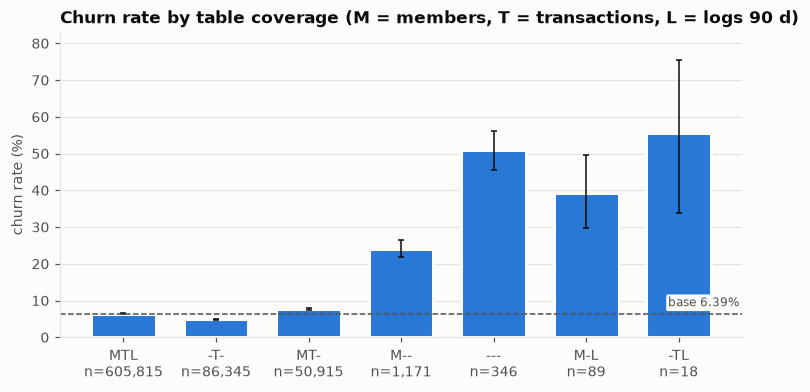

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.6))
C.plot_churn_rate(cov_table, "coverage", ax=ax, base_rate=BASE,
                  title="Churn rate by table coverage (M = members, T = transactions, L = logs 90 d)")
C.save_fig(fig, "00_coverage_churn")
plt.show()

- 81 % of customers appear in all three tables (`MTL`), with a churn rate close to the base (6.4 %).
- **No member record is not a risk signal by itself:** `-T-` (86k customers, 11.6 %) churns *less* than the base, 4.9 %. The 11.6 % without a member row is therefore a population to keep, not noise, and missing demographics must be encoded explicitly rather than imputed as if they were average customers (notebook 01).
- **No listening in 90 days with a member record** (`MT-`, 51k) churns more, 7.8 %: inactivity is a mild signal (notebooks 06–07).
- **No transaction history** (`M--`, `---`, `M-L`; ~1.6k customers) churns at 24–51 %, but it is 0.2 % of the population. These customers cannot have a subscription state, so the state features must be null-aware (a `has_txn` flag), not zero-filled.

## 4. Does the label line up with the expiry date?

KKBox defines the February cohort as customers whose membership **expires in February 2017**; `is_churn = 1` if they do not renew within 30 days of that expiry. We check this with the expiry of the **last transaction** on or before the cutoff (ordered by `transaction_date`, ties by source order), which is the subscription state at the cutoff.

In [10]:
last = (txn.sort("transaction_date", "_ord").group_by("msno")
        .agg(last_expire=pl.col("membership_expire_date").last(),
             max_expire=pl.col("membership_expire_date").max(),
             last_is_cancel=pl.col("is_cancel").last()))
state = (users.join(last, on="msno", how="left")
         .with_columns(last_expire_date=C.to_date("last_expire"), max_expire_date=C.to_date("max_expire")))

print("last expiry differs from the maximum expiry for "
      f"{state.filter(pl.col('last_expire').is_not_null()).select((pl.col('last_expire') != pl.col('max_expire')).mean()).item():.2%} of customers")

def expiry_band(col):
    return (pl.when(pl.col(col).is_null()).then(pl.lit("no txn"))
            .when(pl.col(col) < pl.date(2017, 1, 1)).then(pl.lit("< 2017-01"))
            .when(pl.col(col) < pl.date(2017, 2, 1)).then(pl.lit("2017-01"))
            .when(pl.col(col) < pl.date(2017, 3, 1)).then(pl.lit("2017-02"))
            .when(pl.col(col) < pl.date(2017, 4, 1)).then(pl.lit("2017-03"))
            .otherwise(pl.lit(">= 2017-04")))

BAND_ORDER = ["< 2017-01", "2017-01", "2017-02", "2017-03", ">= 2017-04", "no txn"]
state = state.with_columns(expiry_band=expiry_band("last_expire_date"))
expiry_table = C.churn_rate_by(state, "expiry_band", order=BAND_ORDER)
expiry_table

last expiry differs from the maximum expiry for 1.89% of customers


,expiry_band,n,churners,churn_rate,ci_low,ci_high,share,lift
0,< 2017-01,2384,2067,0.8670,0.8528,0.8801,0.0032,13.5635
1,2017-01,11013,3659,0.3322,0.3235,0.3411,0.0148,5.1975
2,2017-02,660518,36916,0.0559,0.0553,0.0564,0.8870,0.8743
3,2017-03,63502,2186,0.0344,0.0330,0.0359,0.0853,0.5385
4,>= 2017-04,5676,2283,0.4022,0.3895,0.4150,0.0076,6.2922
5,no txn,1606,493,0.3070,0.2849,0.3300,0.0022,4.8022


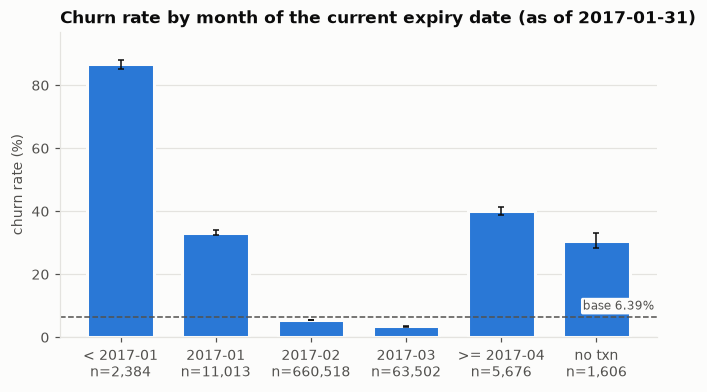

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.6))
C.plot_churn_rate(expiry_table, "expiry_band", ax=ax, base_rate=BASE,
                  title="Churn rate by month of the current expiry date (as of 2017-01-31)")
C.save_fig(fig, "00_expiry_band_churn")
plt.show()

In [12]:
C.churn_rate_by(state.filter(pl.col("last_is_cancel").is_not_null()),
                ["expiry_band", "last_is_cancel"], order=BAND_ORDER)[
    ["expiry_band", "last_is_cancel", "n", "churn_rate"]]

,expiry_band,last_is_cancel,n,churn_rate
0,< 2017-01,0,1008,0.8075
1,< 2017-01,1,1376,0.9106
2,2017-01,0,5391,0.0768
3,2017-01,1,5622,0.5772
4,2017-02,0,658025,0.0538
5,2017-02,1,2493,0.6045
6,2017-03,0,63371,0.0331
7,2017-03,1,131,0.6565
8,>= 2017-04,0,5537,0.3903
9,>= 2017-04,1,139,0.8777


- **88.7 %** of the cohort has its current expiry in February, as the label definition says. The rest is not a data error but a mix of states the label definition does not describe cleanly:
  - **2017-03 (8.5 %, churn 3.4 %)**: customers already paid through March. They are the safest group.
  - **2017-01 or earlier (1.8 %, churn 33–87 %)**: the membership already lapsed at the cutoff; about half of the January group carries a cancellation as the last record.
  - **≥ 2017-04 (0.8 %, churn 40 %)**: long or odd expiry dates (some in 2018–2023); notebook 02 checks whether these are data errors.
- The last record's expiry differs from the maximum expiry for 1.9 % of customers, almost always because a cancellation moved the expiry *back*. The current state must therefore come from the **last** record, not from `max(membership_expire_date)`.
- `last_is_cancel = 1` raises churn to 58–91 % in every band. This is the strongest single signal seen so far and is examined in notebook 03.

## 5. First look at `days_to_expire`

Days from the cutoff to the current expiry. February expiries are 1–28 days away; the bands below follow the calendar instead of deciles, because the distribution is dominated by the February block.

In [13]:
DTE_ORDER = ["expired (< 0)", "0-7", "8-14", "15-21", "22-28", "29-59", "60+", "no txn"]
dte = (pl.col("last_expire_date") - pl.lit(C.CUTOFF)).dt.total_days()
state = state.with_columns(days_to_expire=dte).with_columns(
    dte_band=pl.when(pl.col("days_to_expire").is_null()).then(pl.lit("no txn"))
    .when(pl.col("days_to_expire") < 0).then(pl.lit("expired (< 0)"))
    .when(pl.col("days_to_expire") <= 7).then(pl.lit("0-7"))
    .when(pl.col("days_to_expire") <= 14).then(pl.lit("8-14"))
    .when(pl.col("days_to_expire") <= 21).then(pl.lit("15-21"))
    .when(pl.col("days_to_expire") <= 28).then(pl.lit("22-28"))
    .when(pl.col("days_to_expire") <= 59).then(pl.lit("29-59"))
    .otherwise(pl.lit("60+")))
dte_table = C.churn_rate_by(state, "dte_band", order=DTE_ORDER)
dte_table

,dte_band,n,churners,churn_rate,ci_low,ci_high,share,lift
0,expired (< 0),8426,5503,0.6531,0.6429,0.6632,0.0113,10.2168
1,0-7,155160,9252,0.0596,0.0585,0.0608,0.2084,0.9328
2,8-14,146117,8857,0.0606,0.0594,0.0619,0.1962,0.9483
3,15-21,151828,8910,0.0587,0.0575,0.0599,0.2039,0.9180
4,22-28,212384,10120,0.0476,0.0468,0.0486,0.2852,0.7454
5,29-59,63502,2186,0.0344,0.0330,0.0359,0.0853,0.5385
6,60+,5676,2283,0.4022,0.3895,0.4150,0.0076,6.2922
7,no txn,1606,493,0.3070,0.2849,0.3300,0.0022,4.8022


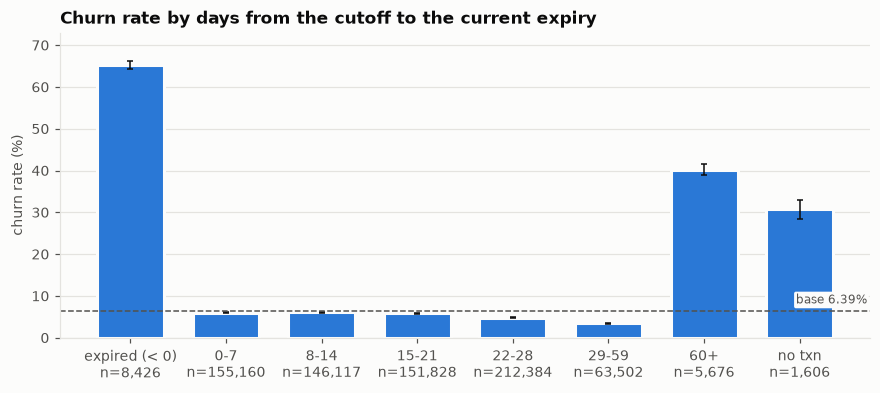

In [14]:
fig, ax = plt.subplots(figsize=(9.5, 3.6))
C.plot_churn_rate(dte_table, "dte_band", ax=ax, base_rate=BASE,
                  title="Churn rate by days from the cutoff to the current expiry")
C.save_fig(fig, "00_days_to_expire_churn")
plt.show()

Inside February the churn rate is almost flat (about 6 % for 0–21 days, 4.8 % for 22–28 days), so a fine-grained `days_to_expire` mostly separates the **non-February states** (already expired, paid through March, far-future expiry). Notebook 03 decides whether to keep it as a number, as bands, or as the expiry-state category built here.

## 6. Conclusions

In [15]:
decisions = C.write_decisions("00", "Population, label and coverage", [
    {"finding": "Both transaction files contain records after 2017-01-31; customers without one churn 100 %",
     "decision": "Every feature uses only `transaction_date <= cutoff` and logs inside the 90-day window (already true in w1/w2 pipelines; keep a test for it)",
     "kind": "cleaning"},
    {"finding": "EDA population = fit split, identical to the indices used by the w1/w2 models",
     "decision": "All later notebooks use `C.load_fit_population()`; stop/tune/March stay unseen",
     "kind": "no action"},
    {"finding": "11.6 % have no member record and churn less than the base (4.9 %)",
     "decision": "Keep them; encode the absence explicitly (`has_member_record`) instead of imputing average demographics",
     "kind": "new feature"},
    {"finding": "0.2 % have no transaction before the cutoff and churn 24-56 %",
     "decision": "Add `has_txn`; subscription-state features stay null (not 0) for them",
     "kind": "new feature"},
    {"finding": "11.3 % of the cohort does not expire in February (lapsed, paid through March, far future) with very different churn",
     "decision": "Candidate categorical `expiry_state` (lapsed / February / March / later / no txn) from the last record; final encoding in notebook 03",
     "kind": "open"},
    {"finding": "Last record's expiry differs from max expiry for 1.9 % (cancellations move it back)",
     "decision": "Current-state features come from the last record (by date, then source order), never from max()",
     "kind": "cleaning"},
    {"finding": "No listening in 90 days with a member record churns 7.8 % vs 6.4 %",
     "decision": "Keep `has_listening_logs`; activity features analysed in notebooks 06-07",
     "kind": "open"},
])
decisions

,finding,decision,kind
0,Both transaction files contain records after 2017-01-31; customers without one churn 100 %,Every feature uses only `transaction_date <= cutoff` and logs inside the 90-day window (already true in w1/w2 pipelines; keep a test for it),cleaning
1,"EDA population = fit split, identical to the indices used by the w1/w2 models",All later notebooks use `C.load_fit_population()`; stop/tune/March stay unseen,no action
2,11.6 % have no member record and churn less than the base (4.9 %),Keep them; encode the absence explicitly (`has_member_record`) instead of imputing average demographics,new feature
3,0.2 % have no transaction before the cutoff and churn 24-56 %,Add `has_txn`; subscription-state features stay null (not 0) for them,new feature
4,"11.3 % of the cohort does not expire in February (lapsed, paid through March, far future) with very different churn",Candidate categorical `expiry_state` (lapsed / February / March / later / no txn) from the last record; final encoding in notebook 03,open
5,Last record's expiry differs from max expiry for 1.9 % (cancellations move it back),"Current-state features come from the last record (by date, then source order), never from max()",cleaning
6,No listening in 90 days with a member record churns 7.8 % vs 6.4 %,Keep `has_listening_logs`; activity features analysed in notebooks 06-07,open


---
**Next:** `01_members.ipynb`